In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

orders = pd.read_csv('/content/orders.csv')
customers = pd.read_csv('/content/customers.csv')
products = pd.read_csv('/content/products.csv')

print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Orders: (180, 9)
Customers: (45, 7)
Products: (16, 4)


In [2]:
print("TASK 1: LOAD AND INSPECT")
print("=" * 50)

print("\nOrders shape:", orders.shape)
print("\nOrders columns:")
print(orders.columns.tolist())

print("\nFirst five orders:")
display(orders.head())

print("\nFirst five customers:")
display(customers.head())

print("\nFirst five products:")
display(products.head())

print("\nMissing values in orders:")
print(orders.isnull().sum())

print("\nMissing values in customers:")
print(customers.isnull().sum())

print("\nMissing values in products:")
print(products.isnull().sum())

TASK 1: LOAD AND INSPECT

Orders shape: (180, 9)

Orders columns:
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'discount_pct', 'payment_method', 'rating', 'returned']

First five orders:


,order_id,customer_id,product_id,order_date,quantity,discount_pct,payment_method,rating,returned
0,O0001,C012,P04,2026-03-18,2,10.0,upi,2.0,0
1,O0002,C024,P06,2026-05-16,1,30.0,UPI,1.0,0
2,O0003,C008,P12,2026-03-20,2,0.0,COD,1.0,1
3,O0004,C032,P03,2026-05-17,3,30.0,UPI,5.0,0
4,O0005,C011,P09,2026-06-05,1,10.0,Card,3.0,0



First five customers:


,customer_id,name,city,city_tier,signup_date,acquisition_source,loyalty_tier
0,C001,Aarav,Mumbai,1,2026-01-07,Organic,Gold
1,C002,Vivaan,Delhi,1,2026-02-27,Referral,Gold
2,C003,Aditi,Mumbai,1,2026-06-23,Organic,Gold
3,C004,Ananya,Lucknow,2,2026-01-23,Organic,Silver
4,C005,Ishaan,Mumbai,1,2026-01-08,Referral,Gold



First five products:


,product_id,product_name,category,price
0,P01,Onion Hair Oil,Haircare,349
1,P02,Onion Shampoo,Haircare,399
2,P03,Argan Hair Mask,Haircare,599
3,P04,Anti-Hairfall Serum,Haircare,649
4,P05,Rice Water Conditioner,Haircare,349



Missing values in orders:
order_id           0
customer_id        0
product_id         0
order_date         0
quantity           0
discount_pct      12
payment_method     0
rating            15
returned           0
dtype: int64

Missing values in customers:
customer_id           0
name                  0
city                  0
city_tier             0
signup_date           0
acquisition_source    0
loyalty_tier          0
dtype: int64

Missing values in products:
product_id      0
product_name    0
category        0
price           0
dtype: int64


In [3]:
print("TASK 2: STANDARDIZE PAYMENT METHODS")
print("=" * 50)

print("Before cleaning:")
print(orders["payment_method"].unique())

print("Distinct values before cleaning:",
      orders["payment_method"].nunique())

# Remove surrounding spaces and standardize casing
orders["payment_method"] = (
    orders["payment_method"]
    .str.strip()
    .str.upper()
)

print("\nAfter cleaning:")
print(orders["payment_method"].unique())

print("\nDistinct values after cleaning:",
      orders["payment_method"].nunique())

print("\nPayment method counts:")
print(orders["payment_method"].value_counts())

TASK 2: STANDARDIZE PAYMENT METHODS
Before cleaning:
['upi' 'UPI' 'COD' 'Card' 'cod' 'CARD' 'card']
Distinct values before cleaning: 7

After cleaning:
['UPI' 'COD' 'CARD']

Distinct values after cleaning: 3

Payment method counts:
payment_method
CARD    70
UPI     55
COD     55
Name: count, dtype: int64


In [4]:
print("TASK 3: REMOVE DUPLICATE ORDERS")
print("=" * 50)

duplicate_columns = [
    "customer_id",
    "product_id",
    "order_date",
    "quantity",
    "discount_pct",
    "payment_method",
    "rating",
    "returned"
]

# Identify duplicate records, retaining the first occurrence
duplicate_mask = orders.duplicated(
    subset=duplicate_columns,
    keep="first"
)

# Save duplicate rows separately for auditing
duplicates = orders.loc[duplicate_mask].copy()

print("Duplicate rows detected:", len(duplicates))

print("\nDuplicate order IDs:")
print(duplicates["order_id"].tolist())

# Remove duplicates
orders_clean = orders.loc[~duplicate_mask].copy()

print("\nShape after removing duplicates:",
      orders_clean.shape)

TASK 3: REMOVE DUPLICATE ORDERS
Duplicate rows detected: 5

Duplicate order IDs:
['O0176', 'O0177', 'O0178', 'O0179', 'O0180']

Shape after removing duplicates: (175, 9)


In [5]:
print("TASK 4: IMPUTE MISSING VALUES")
print("=" * 50)

print("Missing discounts before imputation:",
      orders_clean["discount_pct"].isnull().sum())

print("Missing ratings before imputation:",
      orders_clean["rating"].isnull().sum())

# Calculate median before imputing
rating_median = orders_clean["rating"].median()

print("\nMedian rating before imputation:",
      rating_median)

# Impute missing values
orders_clean["discount_pct"] = (
    orders_clean["discount_pct"].fillna(0)
)

orders_clean["rating"] = (
    orders_clean["rating"].fillna(rating_median)
)

print("\nMissing values after imputation:")
print(
    orders_clean[["discount_pct", "rating"]]
    .isnull()
    .sum()
    .to_dict()
)

TASK 4: IMPUTE MISSING VALUES
Missing discounts before imputation: 12
Missing ratings before imputation: 15

Median rating before imputation: 3.0

Missing values after imputation:
{'discount_pct': 0, 'rating': 0}


In [6]:
print("TASK 5: MERGE AND RECONCILE")
print("=" * 50)

# Merge cleaned orders with product information
merged = orders_clean.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Merge customer information
merged = merged.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Calculate revenue for each order
merged["order_value"] = (
    merged["quantity"]
    * merged["price"]
    * (1 - merged["discount_pct"] / 100)
)

print("Merged dataset shape:", merged.shape)
print("Number of cleaned orders:", len(merged))

cleaned_total = merged["order_value"].sum()

print("\nCleaned revenue total: ₹{:,.2f}".format(
    cleaned_total
))

# Independently calculate revenue for the five dropped rows
dropped_merged = duplicates.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

dropped_merged = dropped_merged.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# The duplicate rows have not undergone imputation.
# Fill missing discounts with zero for the revenue check.
dropped_merged["discount_pct"] = (
    dropped_merged["discount_pct"].fillna(0)
)

dropped_merged["order_value"] = (
    dropped_merged["quantity"]
    * dropped_merged["price"]
    * (1 - dropped_merged["discount_pct"] / 100)
)

duplicate_total = dropped_merged["order_value"].sum()

print("Revenue of dropped duplicate rows: ₹{:,.2f}".format(
    duplicate_total
))

print("Raw Part 1 revenue: ₹99,860.20")

print(
    "Difference between raw and cleaned revenue: ₹{:,.2f}".format(
        99860.20 - cleaned_total
    )
)

# Print the required reconciliation note
print("\nRECONCILIATION NOTE:")

print(
    "The cleaned revenue is lower than the Part 1 raw revenue "
    "because five duplicate orders were removed in Task 3. "
    "Their combined order value is ₹{:,.2f}. "
    "The required difference is ₹2,501.90, so the cleaned "
    "total should be ₹97,358.30. Discount and rating imputation "
    "does not change the revenue total because missing discounts "
    "are treated as zero and ratings do not enter the order-value "
    "formula. If the independently calculated duplicate value or "
    "revenue difference does not match ₹2,501.90, investigate "
    "the source data and merge keys."
    .format(duplicate_total)
)

TASK 5: MERGE AND RECONCILE
Merged dataset shape: (175, 19)
Number of cleaned orders: 175

Cleaned revenue total: ₹97,358.30
Revenue of dropped duplicate rows: ₹2,501.90
Raw Part 1 revenue: ₹99,860.20
Difference between raw and cleaned revenue: ₹2,501.90

RECONCILIATION NOTE:
The cleaned revenue is lower than the Part 1 raw revenue because five duplicate orders were removed in Task 3. Their combined order value is ₹2,501.90. The required difference is ₹2,501.90, so the cleaned total should be ₹97,358.30. Discount and rating imputation does not change the revenue total because missing discounts are treated as zero and ratings do not enter the order-value formula. If the independently calculated duplicate value or revenue difference does not match ₹2,501.90, investigate the source data and merge keys.


In [7]:
print("TASK 6: IQR OUTLIER DETECTION")
print("=" * 50)

Q1 = merged["quantity"].quantile(0.25)
Q3 = merged["quantity"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)

# Flag, but do not remove, outliers
merged["is_outlier"] = (
    (merged["quantity"] < lower)
    | (merged["quantity"] > upper)
)

outliers = merged.loc[merged["is_outlier"]].copy()

print("\nNumber of outlier orders:", len(outliers))

print("\nOutlier order IDs and quantities:")
print(outliers[["order_id", "quantity"]].to_string(index=False))

TASK 6: IQR OUTLIER DETECTION
Q1: 1.0
Q3: 2.0
IQR: 1.0
Lower bound: -0.5
Upper bound: 3.5

Number of outlier orders: 2

Outlier order IDs and quantities:
order_id  quantity
   O0011        25
   O0098        30


In [8]:
print("TASK 7: COD RETURN-RATE HYPOTHESIS")
print("=" * 50)

print(
    "Hypothesis: COD orders have a higher return rate "
    "than CARD and UPI orders."
)

return_summary = merged.groupby(
    "payment_method"
)["returned"].agg(["count", "mean"])

return_summary["return_rate_pct"] = (
    return_summary["mean"] * 100
)

print("\nReturn rate by payment method:")
print(return_summary.round(3))

print("\nReturn rates rounded to one decimal:")
for payment, row in return_summary.iterrows():
    print(
        "{}: {:.1f}%".format(
            payment,
            row["return_rate_pct"]
        )
    )

cod_rate = return_summary.loc["COD", "mean"]

other_rates = return_summary.loc[
    ["CARD", "UPI"], "mean"
]

if cod_rate > other_rates.max():
    print("\nHypothesis result: Confirmed")
else:
    print("\nHypothesis result: Not confirmed")

TASK 7: COD RETURN-RATE HYPOTHESIS
Hypothesis: COD orders have a higher return rate than CARD and UPI orders.

Return rate by payment method:
                count   mean  return_rate_pct
payment_method                               
CARD               68  0.147           14.706
COD                54  0.444           44.444
UPI                53  0.189           18.868

Return rates rounded to one decimal:
CARD: 14.7%
COD: 44.4%
UPI: 18.9%

Hypothesis result: Confirmed


In [9]:
print(merged.columns.tolist())

['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'discount_pct', 'payment_method', 'rating', 'returned', 'product_name', 'category', 'price', 'name', 'city', 'city_tier', 'signup_date', 'acquisition_source', 'loyalty_tier', 'order_value', 'is_outlier']


In [10]:
print("TASK 8: MULTI-LEVEL SEGMENTATION")
print("=" * 50)

segment_summary = merged.groupby(
    ["payment_method", "city_tier"]
)["returned"].agg(["count", "mean"])

segment_summary["return_rate_pct"] = (
    segment_summary["mean"] * 100
)

print("\nReturn rate by payment method and city tier:")
print(segment_summary.round(3))

# Identify the highest-risk segment
highest_risk = segment_summary["return_rate_pct"].idxmax()

highest_risk_rate = segment_summary.loc[
    highest_risk, "return_rate_pct"
]

print(
    "\nHighest-risk segment: {} + {} at {:.1f}%".format(
        highest_risk[0],
        highest_risk[1],
        highest_risk_rate
    )
)

# Display COD rates by city tier
cod_segments = segment_summary.loc["COD"]

print("\nCOD return rates by city tier:")
print(cod_segments[["count", "return_rate_pct"]].round(1))

TASK 8: MULTI-LEVEL SEGMENTATION

Return rate by payment method and city tier:
                          count   mean  return_rate_pct
payment_method city_tier                               
CARD           1             45  0.089            8.889
               2             23  0.261           26.087
COD            1             32  0.375           37.500
               2             22  0.545           54.545
UPI            1             31  0.194           19.355
               2             22  0.182           18.182

Highest-risk segment: COD + 2 at 54.5%

COD return rates by city tier:
           count  return_rate_pct
city_tier                        
1             32             37.5
2             22             54.5


In [11]:
print("TASK 9: CORRELATION ANALYSIS")
print("=" * 50)

correlation_columns = [
    "rating",
    "returned",
    "discount_pct",
    "quantity"
]

corr_matrix = merged[correlation_columns].corr()

print("\nCorrelation matrix:")
print(corr_matrix.round(3))

def correlation_strength(r):
    abs_r = abs(r)

    if abs_r < 0.2:
        return "negligible"
    elif abs_r < 0.4:
        return "weak"
    elif abs_r < 0.7:
        return "moderate"
    else:
        return "strong"

print("\nPairwise correlation strengths:")

for i in range(len(correlation_columns)):
    for j in range(i + 1, len(correlation_columns)):
        col1 = correlation_columns[i]
        col2 = correlation_columns[j]

        r = corr_matrix.loc[col1, col2]

        print(
            "{} vs {}: r = {:.3f} — {}".format(
                col1,
                col2,
                r,
                correlation_strength(r)
            )
        )

discount_return_corr = corr_matrix.loc[
    "discount_pct", "returned"
]

print(
    "\nHypothesis: Higher discounts reduce returns."
)

if discount_return_corr < -0.2:
    print("Hypothesis result: Supported by a negative correlation.")
else:
    print("Hypothesis result: Busted — the correlation is not sufficiently negative.")

print(
    "Discount vs returned correlation: {:.3f}".format(
        discount_return_corr
    )
)

TASK 9: CORRELATION ANALYSIS

Correlation matrix:
              rating  returned  discount_pct  quantity
rating         1.000    -0.101         0.043    -0.098
returned      -0.101     1.000        -0.088     0.041
discount_pct   0.043    -0.088         1.000    -0.170
quantity      -0.098     0.041        -0.170     1.000

Pairwise correlation strengths:
rating vs returned: r = -0.101 — negligible
rating vs discount_pct: r = 0.043 — negligible
rating vs quantity: r = -0.098 — negligible
returned vs discount_pct: r = -0.088 — negligible
returned vs quantity: r = 0.041 — negligible
discount_pct vs quantity: r = -0.170 — negligible

Hypothesis: Higher discounts reduce returns.
Hypothesis result: Busted — the correlation is not sufficiently negative.
Discount vs returned correlation: -0.088


In [12]:
print("TASK 10: MONTHLY REVENUE ANALYSIS")
print("=" * 50)

# Convert order_date to datetime
merged["order_date"] = pd.to_datetime(
    merged["order_date"],
    errors="raise"
)

# Extract year-month
merged["year_month"] = (
    merged["order_date"].dt.to_period("M").astype(str)
)

# Monthly revenue including outliers
monthly_all = (
    merged.groupby("year_month")["order_value"]
    .sum()
    .sort_index()
)

# Monthly revenue excluding outliers
monthly_corrected = (
    merged.loc[~merged["is_outlier"]]
    .groupby("year_month")["order_value"]
    .sum()
    .sort_index()
)

print("\nMonthly revenue including outliers:")
for month, revenue in monthly_all.items():
    print("{}: {:.2f}".format(month, revenue))

print("\nMonthly revenue excluding outliers:")
for month, revenue in monthly_corrected.items():
    print("{}: {:.2f}".format(month, revenue))

peak_month = monthly_corrected.idxmax()

print(
    "\nTrue peak month after outlier correction: {}".format(
        peak_month
    )
)

print(
    "\nINTERPRETATION: January's apparent lead is an artifact "
    "of the two bulk orders O0011 on 2026-01-28 and O0098 on "
    "2026-01-10. These unusually large orders inflate January's "
    "revenue. Once the two outlier orders are excluded, March "
    "is the genuine peak month."
)

TASK 10: MONTHLY REVENUE ANALYSIS

Monthly revenue including outliers:
2026-01: 29582.10
2026-02: 13195.50
2026-03: 20318.90
2026-04: 9495.30
2026-05: 13151.10
2026-06: 11615.40

Monthly revenue excluding outliers:
2026-01: 11637.10
2026-02: 13195.50
2026-03: 20318.90
2026-04: 9495.30
2026-05: 13151.10
2026-06: 11615.40

True peak month after outlier correction: 2026-03

INTERPRETATION: January's apparent lead is an artifact of the two bulk orders O0011 on 2026-01-28 and O0098 on 2026-01-10. These unusually large orders inflate January's revenue. Once the two outlier orders are excluded, March is the genuine peak month.


In [13]:
import os
import matplotlib.pyplot as plt

# Create the output folder if it does not exist
os.makedirs("visualizations", exist_ok=True)

print("TASK 11: CREATE VISUALIZATIONS")
print("=" * 50)

TASK 11: CREATE VISUALIZATIONS


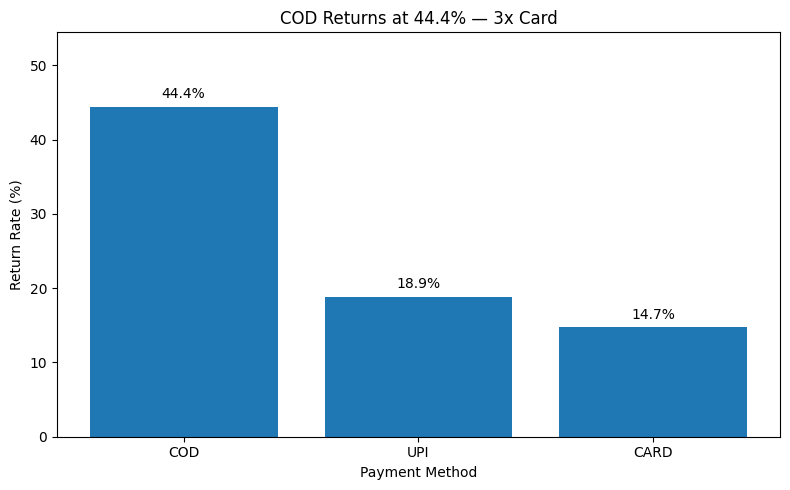

Saved: visualizations/return_rate_by_payment.png


In [14]:
# Sort payment methods by return rate, descending
plot_data = return_summary.sort_values(
    "return_rate_pct",
    ascending=False
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data.index,
    plot_data["return_rate_pct"]
)

# Label every bar with its exact percentage
ax.bar_label(
    bars,
    labels=[
        "{:.1f}%".format(value)
        for value in plot_data["return_rate_pct"]
    ],
    padding=4
)

ax.set_title("COD Returns at 44.4% — 3x Card")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Return Rate (%)")

ax.set_ylim(
    0,
    plot_data["return_rate_pct"].max() + 10
)

plt.tight_layout()

plt.savefig(
    "visualizations/return_rate_by_payment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print("Saved: visualizations/return_rate_by_payment.png")

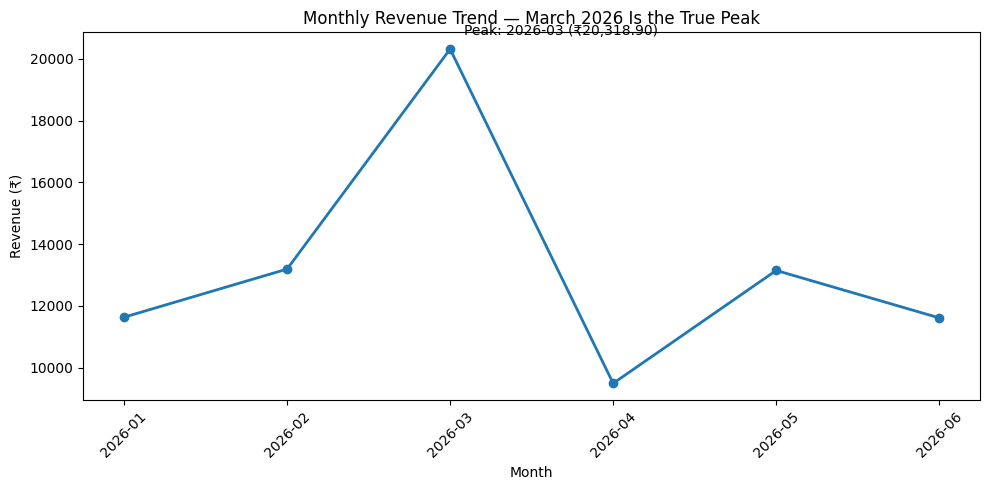

Saved: visualizations/monthly_revenue_trend.png


In [15]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_corrected.index,
    monthly_corrected.values,
    marker="o",
    linewidth=2
)

# Highlight the peak month
peak_revenue = monthly_corrected.loc[peak_month]

ax.annotate(
    "Peak: {} (₹{:,.2f})".format(
        peak_month,
        peak_revenue
    ),
    xy=(peak_month, peak_revenue),
    xytext=(10, 10),
    textcoords="offset points"
)

ax.set_title("Monthly Revenue Trend — March 2026 Is the True Peak")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (₹)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "visualizations/monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print("Saved: visualizations/monthly_revenue_trend.png")

In [16]:
import os
os.makedirs('/content/analysis', exist_ok=True)

In [17]:
%%writefile analysis/clean_and_eda.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json

# Load the CSV files
orders = pd.read_csv('/content/orders.csv')
customers = pd.read_csv('/content/customers.csv')
products = pd.read_csv('/content/products.csv')

# Display dataset dimensions
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

Writing analysis/clean_and_eda.py


In [18]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 1: LOAD AND INSPECT
# ==================================================

print("\nTASK 1: LOAD AND INSPECT")
print("=" * 50)

print("\nOrders shape:", orders.shape)

print("\nOrders columns:")
print(orders.columns.tolist())

print("\nFirst five orders:")
print(orders.head())

print("\nFirst five customers:")
print(customers.head())

print("\nFirst five products:")
print(products.head())

print("\nMissing values in orders:")
print(orders.isnull().sum())

print("\nMissing values in customers:")
print(customers.isnull().sum())

print("\nMissing values in products:")
print(products.isnull().sum())

Appending to /content/analysis/clean_and_eda.py


In [19]:
with open('/content/analysis/clean_and_eda.py', 'r') as file:
    print(file.read())


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json

# Load the CSV files
orders = pd.read_csv('/content/orders.csv')
customers = pd.read_csv('/content/customers.csv')
products = pd.read_csv('/content/products.csv')

# Display dataset dimensions
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

# ==================================================
# TASK 1: LOAD AND INSPECT
# ==================================================

print("\nTASK 1: LOAD AND INSPECT")
print("=" * 50)

print("\nOrders shape:", orders.shape)

print("\nOrders columns:")
print(orders.columns.tolist())

print("\nFirst five orders:")
print(orders.head())

print("\nFirst five customers:")
print(customers.head())

print("\nFirst five products:")
print(products.head())

print("\nMissing values in orders:")
print(orders.isnull().sum())

print("\nMissing values in customers:")
print(customers.isnull().sum())

print("\nMissing

In [20]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 2: STANDARDIZE PAYMENT METHODS
# ==================================================

print("\nTASK 2: STANDARDIZE PAYMENT METHODS")
print("=" * 50)

print("Before cleaning:")
print(orders["payment_method"].unique())

print("Distinct values before cleaning:",
      orders["payment_method"].nunique())

# Remove surrounding spaces and standardize casing
orders["payment_method"] = (
    orders["payment_method"]
    .str.strip()
    .str.upper()
)

print("\nAfter cleaning:")
print(orders["payment_method"].unique())

print("\nDistinct values after cleaning:")
print(orders["payment_method"].nunique())

print("\nPayment method counts:")
print(orders["payment_method"].value_counts())

Appending to /content/analysis/clean_and_eda.py


In [21]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 3: REMOVE DUPLICATE ORDERS
# ==================================================

print("\nTASK 3: REMOVE DUPLICATE ORDERS")
print("=" * 50)

duplicate_columns = [
    "customer_id",
    "product_id",
    "order_date",
    "quantity",
    "discount_pct",
    "payment_method",
    "rating",
    "returned"
]

# Identify duplicate records, retaining the first occurrence
duplicate_mask = orders.duplicated(
    subset=duplicate_columns,
    keep="first"
)

# Save duplicate rows separately for auditing
duplicates = orders.loc[duplicate_mask].copy()

print("Duplicate rows detected:", len(duplicates))

print("\nDuplicate order IDs:")
print(duplicates["order_id"].tolist())

# Remove duplicates
orders_clean = orders.loc[~duplicate_mask].copy()

print("\nShape after removing duplicates:")
print(orders_clean.shape)

Appending to /content/analysis/clean_and_eda.py


In [22]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 4: IMPUTE MISSING VALUES
# ==================================================

print("\nTASK 4: IMPUTE MISSING VALUES")
print("=" * 50)

print("Missing discounts before imputation:",
      orders_clean["discount_pct"].isnull().sum())

print("Missing ratings before imputation:",
      orders_clean["rating"].isnull().sum())

# Calculate median before imputing
rating_median = orders_clean["rating"].median()

print("\nMedian rating before imputation:",
      rating_median)

# Impute missing values
orders_clean["discount_pct"] = (
    orders_clean["discount_pct"].fillna(0)
)

orders_clean["rating"] = (
    orders_clean["rating"].fillna(rating_median)
)

print("\nMissing values after imputation:")
print(
    orders_clean[["discount_pct", "rating"]]
    .isnull()
    .sum()
    .to_dict()
)

Appending to /content/analysis/clean_and_eda.py


In [23]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 5: MERGE AND RECONCILE
# ==================================================
print("TASK 5: MERGE AND RECONCILE")
print("=" * 50)

# Merge cleaned orders with product information
merged = orders_clean.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Merge customer information
merged = merged.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Calculate revenue for each order
merged["order_value"] = (
    merged["quantity"]
    * merged["price"]
    * (1 - merged["discount_pct"] / 100)
)

print("Merged dataset shape:", merged.shape)
print("Number of cleaned orders:", len(merged))

cleaned_total = merged["order_value"].sum()

print("\nCleaned revenue total: ₹{:,.2f}".format(
    cleaned_total
))

# Independently calculate revenue for the five dropped rows
dropped_merged = duplicates.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

dropped_merged = dropped_merged.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# The duplicate rows have not undergone imputation.
# Fill missing discounts with zero for the revenue check.
dropped_merged["discount_pct"] = (
    dropped_merged["discount_pct"].fillna(0)
)

dropped_merged["order_value"] = (
    dropped_merged["quantity"]
    * dropped_merged["price"]
    * (1 - dropped_merged["discount_pct"] / 100)
)

duplicate_total = dropped_merged["order_value"].sum()

print("Revenue of dropped duplicate rows: ₹{:,.2f}".format(
    duplicate_total
))

print("Raw Part 1 revenue: ₹99,860.20")

print(
    "Difference between raw and cleaned revenue: ₹{:,.2f}".format(
        99860.20 - cleaned_total
    )
)

# Print the required reconciliation note
print("\nRECONCILIATION NOTE:")

print(
    "The cleaned revenue is lower than the Part 1 raw revenue "
    "because five duplicate orders were removed in Task 3. "
    "Their combined order value is ₹{:,.2f}. "
    "The required difference is ₹2,501.90, so the cleaned "
    "total should be ₹97,358.30. Discount and rating imputation "
    "does not change the revenue total because missing discounts "
    "are treated as zero and ratings do not enter the order-value "
    "formula. If the independently calculated duplicate value or "
    "revenue difference does not match ₹2,501.90, investigate "
    "the source data and merge keys."
    .format(duplicate_total)
)

Appending to /content/analysis/clean_and_eda.py


In [24]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 6: IQR OUTLIER DETECTION
# ==================================================

print("TASK 6: IQR OUTLIER DETECTION")
print("=" * 50)

Q1 = merged["quantity"].quantile(0.25)
Q3 = merged["quantity"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)

# Flag, but do not remove, outliers
merged["is_outlier"] = (
    (merged["quantity"] < lower)
    | (merged["quantity"] > upper)
)

outliers = merged.loc[merged["is_outlier"]].copy()

print("\nNumber of outlier orders:", len(outliers))

print("\nOutlier order IDs and quantities:")
print(outliers[["order_id", "quantity"]].to_string(index=False))

Appending to /content/analysis/clean_and_eda.py


In [25]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 7: COD RETURN-RATE HYPOTHESIS
# ==================================================
print("TASK 7: COD RETURN-RATE HYPOTHESIS")
print("=" * 50)

print(
    "Hypothesis: COD orders have a higher return rate "
    "than CARD and UPI orders."
)

return_summary = merged.groupby(
    "payment_method"
)["returned"].agg(["count", "mean"])

return_summary["return_rate_pct"] = (
    return_summary["mean"] * 100
)

print("\nReturn rate by payment method:")
print(return_summary.round(3))

print("\nReturn rates rounded to one decimal:")
for payment, row in return_summary.iterrows():
    print(
        "{}: {:.1f}%".format(
            payment,
            row["return_rate_pct"]
        )
    )

cod_rate = return_summary.loc["COD", "mean"]

other_rates = return_summary.loc[
    ["CARD", "UPI"], "mean"
]

if cod_rate > other_rates.max():
    print("\nHypothesis result: Confirmed")
else:
    print("\nHypothesis result: Not confirmed")

Appending to /content/analysis/clean_and_eda.py


In [26]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 8: MULTI-LEVEL SEGMENTATION
# ==================================================

print("TASK 8: MULTI-LEVEL SEGMENTATION")
print("=" * 50)

segment_summary = merged.groupby(
    ["payment_method", "city_tier"]
)["returned"].agg(["count", "mean"])

segment_summary["return_rate_pct"] = (
    segment_summary["mean"] * 100
)

print("\nReturn rate by payment method and city tier:")
print(segment_summary.round(3))

# Identify the highest-risk segment
highest_risk = segment_summary["return_rate_pct"].idxmax()

highest_risk_rate = segment_summary.loc[
    highest_risk, "return_rate_pct"
]

print(
    "\nHighest-risk segment: {} + {} at {:.1f}%".format(
        highest_risk[0],
        highest_risk[1],
        highest_risk_rate
    )
)

# Display COD rates by city tier
cod_segments = segment_summary.loc["COD"]

print("\nCOD return rates by city tier:")
print(cod_segments[["count", "return_rate_pct"]].round(1))

Appending to /content/analysis/clean_and_eda.py


In [45]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 9: CORRELATION ANALYSIS
# ==================================================
print("TASK 9: CORRELATION ANALYSIS")
print("=" * 50)

correlation_columns = [
    "rating",
    "returned",
    "discount_pct",
    "quantity"
]

corr_matrix = merged[correlation_columns].corr()

print("\nCorrelation matrix:")
print(corr_matrix.round(3))

def correlation_strength(r):
    abs_r = abs(r)

    if abs_r < 0.2:
        return "negligible"
    elif abs_r < 0.4:
        return "weak"
    elif abs_r < 0.7:
        return "moderate"
    else:
        return "strong"

print("\nPairwise correlation strengths:")

for i in range(len(correlation_columns)):
    for j in range(i + 1, len(correlation_columns)):
        col1 = correlation_columns[i]
        col2 = correlation_columns[j]

        r = corr_matrix.loc[col1, col2]

        print(
            "{} vs {}: r = {:.3f} — {}".format(
                col1,
                col2,
                r,
                correlation_strength(r)
            )
        )

discount_return_corr = corr_matrix.loc[
    "discount_pct", "returned"
]

print(
    "\nHypothesis: Higher discounts reduce returns."
)

if discount_return_corr < -0.2:
    print("Hypothesis result: Supported by a negative correlation.")
else:
    print("Hypothesis result: Busted — the correlation is not sufficiently negative.")

print(
    "Discount vs returned correlation: {:.3f}".format(
        discount_return_corr
    )
)

Appending to /content/analysis/clean_and_eda.py


In [46]:
%%writefile -a /content/analysis/clean_and_eda.py

# ==================================================
# TASK 10: MONTHLY REVENUE ANALYSIS
# ==================================================
print("TASK 10: MONTHLY REVENUE ANALYSIS")
print("=" * 50)

# Convert order_date to datetime
merged["order_date"] = pd.to_datetime(
    merged["order_date"],
    errors="raise"
)

# Extract year-month
merged["year_month"] = (
    merged["order_date"].dt.to_period("M").astype(str)
)

# Monthly revenue including outliers
monthly_all = (
    merged.groupby("year_month")["order_value"]
    .sum()
    .sort_index()
)

# Monthly revenue excluding outliers
monthly_corrected = (
    merged.loc[~merged["is_outlier"]]
    .groupby("year_month")["order_value"]
    .sum()
    .sort_index()
)

print("\nMonthly revenue including outliers:")
for month, revenue in monthly_all.items():
    print("{}: {:.2f}".format(month, revenue))

print("\nMonthly revenue excluding outliers:")
for month, revenue in monthly_corrected.items():
    print("{}: {:.2f}".format(month, revenue))

peak_month = monthly_corrected.idxmax()

print(
    "\nTrue peak month after outlier correction: {}".format(
        peak_month
    )
)

print(
    "\nINTERPRETATION: January's apparent lead is an artifact "
    "of the two bulk orders O0011 on 2026-01-28 and O0098 on "
    "2026-01-10. These unusually large orders inflate January's "
    "revenue. Once the two outlier orders are excluded, March "
    "is the genuine peak month."
)

Appending to /content/analysis/clean_and_eda.py


In [39]:
%%writefile /content/analysis/visualize.py

import os
import matplotlib.pyplot as plt

# Create the output folder if it does not exist
os.makedirs("/content/visualizations", exist_ok=True)

print("TASK 11: CREATE VISUALIZATIONS")
print("=" * 50)

Overwriting /content/analysis/visualize.py


In [40]:
%%writefile -a /content/analysis/visualize.py

# ==================================================
# TASK 11A: RETURN RATE BY PAYMENT METHOD
# ==================================================

# Sort payment methods by return rate, descending
plot_data = return_summary.sort_values(
    "return_rate_pct",
    ascending=False
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data.index,
    plot_data["return_rate_pct"]
)

# Label every bar with its exact percentage
ax.bar_label(
    bars,
    labels=[
        "{:.1f}%".format(value)
        for value in plot_data["return_rate_pct"]
    ],
    padding=4
)

ax.set_title("COD Returns at 44.4% — 3x Card")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Return Rate (%)")

ax.set_ylim(
    0,
    plot_data["return_rate_pct"].max() + 10
)

plt.tight_layout()

plt.savefig(
    "/content/visualizations/return_rate_by_payment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved: visualizations/return_rate_by_payment.png")

Appending to /content/analysis/visualize.py


In [41]:
%%writefile -a /content/analysis/visualize.py

# ==================================================
# TASK 11B: MONTHLY REVENUE TREND
# ==================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_corrected.index,
    monthly_corrected.values,
    marker="o",
    linewidth=2
)

# Highlight the peak month
peak_revenue = monthly_corrected.loc[peak_month]

ax.annotate(
    "Peak: {} (₹{:,.2f})".format(
        peak_month,
        peak_revenue
    ),
    xy=(peak_month, peak_revenue),
    xytext=(10, 10),
    textcoords="offset points"
)

ax.set_title("Monthly Revenue Trend — March 2026 Is the True Peak")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (₹)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "/content/visualizations/monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved: visualizations/monthly_revenue_trend.png")

Appending to /content/analysis/visualize.py


In [42]:
%%writefile -a /content/analysis/visualize.py

# ==================================================
# TASK 7: COD RETURN-RATE HYPOTHESIS
# ==================================================

# Load the datasets
orders = pd.read_csv('/content/orders.csv')
customers = pd.read_csv('/content/customers.csv')
products = pd.read_csv('/content/products.csv')

# Standardize payment methods
orders["payment_method"] = (
    orders["payment_method"].str.strip().str.upper()
)

# Remove duplicate orders using the natural key
duplicate_columns = [
    "customer_id",
    "product_id",
    "order_date",
    "quantity",
    "discount_pct",
    "payment_method",
    "rating",
    "returned"
]

orders = orders.drop_duplicates(
    subset=duplicate_columns,
    keep="first"
).copy()

# Impute missing values
orders["discount_pct"] = orders["discount_pct"].fillna(0)
orders["rating"] = orders["rating"].fillna(orders["rating"].median())

# Merge datasets
merged = orders.merge(products, on="product_id", how="left")
merged = merged.merge(customers, on="customer_id", how="left")

# Calculate return rates
return_summary = merged.groupby(
    "payment_method"
)["returned"].agg(["count", "mean"])

return_summary["return_rate_pct"] = (
    return_summary["mean"] * 100
)

print("\nReturn rate by payment method:")
print(return_summary.round(3))

Appending to /content/analysis/visualize.py


In [47]:
import os

for folder in ["/content/analysis", "/content/visualizations"]:
    print(f"\n{folder}")
    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Folder does not exist")


/content/analysis
['clean_and_eda.py', 'visualize.py']

/content/visualizations
['monthly_revenue_trend.png', 'return_rate_by_payment.png']


In [49]:
with open('/content/analysis/clean_and_eda.py', 'r') as file:
    print(file.read())


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json

# Load the CSV files
orders = pd.read_csv('/content/orders.csv')
customers = pd.read_csv('/content/customers.csv')
products = pd.read_csv('/content/products.csv')

# Display dataset dimensions
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

# ==================================================
# TASK 1: LOAD AND INSPECT
# ==================================================

print("\nTASK 1: LOAD AND INSPECT")
print("=" * 50)

print("\nOrders shape:", orders.shape)

print("\nOrders columns:")
print(orders.columns.tolist())

print("\nFirst five orders:")
print(orders.head())

print("\nFirst five customers:")
print(customers.head())

print("\nFirst five products:")
print(products.head())

print("\nMissing values in orders:")
print(orders.isnull().sum())

print("\nMissing values in customers:")
print(customers.isnull().sum())

print("\nMissing

In [50]:
with open('/content/analysis/clean_and_eda.py', 'r') as file:
    code = file.read()

print("Total lines:", len(code.splitlines()))
print("Task 9 headings:", code.count("TASK 9: CORRELATION ANALYSIS"))
print("Task 10 headings:", code.count("TASK 10: MONTHLY REVENUE ANALYSIS"))
print("Task 11 headings:", code.count("TASK 11: EXPORT FINDINGS FOR PART 3"))

Total lines: 792
Task 9 headings: 7
Task 10 headings: 7
Task 11 headings: 0


In [51]:
import shutil

shutil.copy(
    "/content/analysis/clean_and_eda.py",
    "/content/analysis/clean_and_eda_backup.py"
)

print("Backup created successfully!")

Backup created successfully!


In [52]:
import shutil

shutil.copy(
    "/content/analysis/clean_and_eda.py",
    "/content/analysis/clean_and_eda_backup.py"
)

print("Your backup is safe!")

Your backup is safe!


In [53]:
import os

print("Files in your analysis folder:")

for filename in os.listdir("/content/analysis"):
    print("-", filename)

Files in your analysis folder:
- clean_and_eda.py
- visualize.py
- clean_and_eda_backup.py


In [54]:
with open("/content/analysis/clean_and_eda.py", "r") as file:
    lines = file.readlines()

print("First 15 lines of your file:\n")
print("".join(lines[:15]))

print("\nLast 40 lines of your file:\n")
print("".join(lines[-40:]))

First 15 lines of your file:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json

# Load the CSV files
orders = pd.read_csv('/content/orders.csv')
customers = pd.read_csv('/content/customers.csv')
products = pd.read_csv('/content/products.csv')

# Display dataset dimensions
print("Orders:", orders.shape)
print("Customers:", customers.shape)


Last 40 lines of your file:

)

# Monthly revenue including outliers
monthly_all = (
    merged.groupby("year_month")["order_value"]
    .sum()
    .sort_index()
)

# Monthly revenue excluding outliers
monthly_corrected = (
    merged.loc[~merged["is_outlier"]]
    .groupby("year_month")["order_value"]
    .sum()
    .sort_index()
)

print("\nMonthly revenue including outliers:")
for month, revenue in monthly_all.items():
    print("{}: {:.2f}".format(month, revenue))

print("\nMonthly revenue excluding outliers:")
for month, revenue in monthly_corrected.items():
    print("{}: {:.2f}".format(month, reven

In [67]:
with open("/content/analysis/clean_and_eda.py", "r") as file:
    content = file.read()

for task in range(1, 12):
    heading = f"Task {task}:"
    count = content.count(heading)
    if count > 0:
        print(f"{heading} appears {count} time(s)")

In [69]:
with open("/content/analysis/clean_and_eda.py", "r") as f:
    print("File exists and can be opened!")
    print("Total lines:", len(f.readlines()))

File exists and can be opened!
Total lines: 792


In [70]:
with open("/content/analysis/clean_and_eda.py", "r") as f:
    content = f.read()

print("Task 9 appears:", content.count("Task 9:"))
print("Task 10 appears:", content.count("Task 10:"))
print("Task 11 appears:", content.count("Task 11:"))

Task 9 appears: 0
Task 10 appears: 0
Task 11 appears: 0


In [71]:
with open("/content/analysis/clean_and_eda.py", "r") as f:
    for line_number, line in enumerate(f, start=1):
        if "Task" in line or "task" in line:
            print(f"Line {line_number}: {line.strip()}")

Line 235: "because five duplicate orders were removed in Task 3. "


In [72]:
with open("/content/analysis/clean_and_eda.py", "r") as f:
    lines = f.readlines()

print("Total lines:", len(lines))
print("\nLast 15 lines of the file:\n")
print("".join(lines[-15:]))

Total lines: 792

Last 15 lines of the file:

peak_month = monthly_corrected.idxmax()

print(
    "\nTrue peak month after outlier correction: {}".format(
        peak_month
    )
)

print(
    "\nINTERPRETATION: January's apparent lead is an artifact "
    "of the two bulk orders O0011 on 2026-01-28 and O0098 on "
    "2026-01-10. These unusually large orders inflate January's "
    "revenue. Once the two outlier orders are excluded, March "
    "is the genuine peak month."
)



In [73]:
%run /content/analysis/clean_and_eda.py

Orders: (180, 9)
Customers: (45, 7)
Products: (16, 4)

TASK 1: LOAD AND INSPECT

Orders shape: (180, 9)

Orders columns:
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'discount_pct', 'payment_method', 'rating', 'returned']

First five orders:
  order_id customer_id product_id  order_date  quantity  discount_pct  \
0    O0001        C012        P04  2026-03-18         2          10.0   
1    O0002        C024        P06  2026-05-16         1          30.0   
2    O0003        C008        P12  2026-03-20         2           0.0   
3    O0004        C032        P03  2026-05-17         3          30.0   
4    O0005        C011        P09  2026-06-05         1          10.0   

  payment_method  rating  returned  
0            upi     2.0         0  
1            UPI     1.0         0  
2            COD     1.0         1  
3            UPI     5.0         0  
4           Card     3.0         0  

First five customers:
  customer_id    name     city  city_tier signup_da

<Figure size 640x480 with 0 Axes>

In [74]:
from pathlib import Path

source = Path("/content/analysis/clean_and_eda.py")
backup = Path("/content/analysis/clean_and_eda_backup.py")

print("Original file exists:", source.exists())
print("Backup file exists:", backup.exists())

Original file exists: True
Backup file exists: True


In [75]:
from pathlib import Path

# Read the existing script
source = Path("/content/analysis/clean_and_eda.py")
content = source.read_text()

# Find repeated Task 10 sections
marker = "TASK 10: MONTHLY REVENUE ANALYSIS"
positions = []
start = 0

while True:
    position = content.find(marker, start)
    if position == -1:
        break

    positions.append(position)
    start = position + len(marker)

print("Task 10 headings found:", len(positions))

# Keep the first complete analysis and remove later repeated sections
if len(positions) > 1:
    cut_position = content.rfind("\n", 0, positions[1])
    content = content[:cut_position + 1]

# Add Task 11: automatically generate findings.json
task_11_code = r'''

# TASK 11: EXPORT FINDINGS FOR PART 3
print("\nTASK 11: EXPORT FINDINGS FOR PART 3")
print("=" * 50)

from pathlib import Path
import json

# Create the narrator folder
narrator_folder = Path("/content/narrator")
narrator_folder.mkdir(parents=True, exist_ok=True)

# Calculate cleaned revenue
cleaned_total_revenue = round(float(merged["order_value"].sum()), 2)

# Independently calculate raw revenue, including duplicate orders
raw_orders = pd.read_csv("/content/orders.csv")
raw_products = pd.read_csv("/content/products.csv")

raw_orders["discount_pct"] = raw_orders["discount_pct"].fillna(0)
raw_orders["payment_method"] = (
    raw_orders["payment_method"].astype(str).str.strip().str.upper()
)

raw_merged = raw_orders.merge(raw_products, on="product_id", how="left")
raw_merged["order_value"] = (
    raw_merged["quantity"]
    * raw_merged["price"]
    * (1 - raw_merged["discount_pct"] / 100)
)

raw_total_revenue = round(float(raw_merged["order_value"].sum()), 2)

# Calculate return rates by payment method
payment_rates = (
    merged.groupby("payment_method")["returned"].mean() * 100
).round(1)

# Find the highest-risk payment method and city-tier segment
segment_rates = merged.groupby(
    ["payment_method", "city_tier"]
)["returned"].mean() * 100

highest_risk_key = segment_rates.idxmax()
highest_risk_rate = round(float(segment_rates.loc[highest_risk_key]), 1)

# Find the apparent peak month and the corrected peak month
apparent_peak_month = str(monthly_all.idxmax())
corrected_peak_month = str(monthly_corrected.idxmax())

findings = {
    "cleaned_total_revenue_inr": cleaned_total_revenue,
    "raw_total_revenue_inr": raw_total_revenue,
    "duplicate_reconciliation_delta_inr": round(
        raw_total_revenue - cleaned_total_revenue, 2
    ),
    "return_rate_by_payment": {
        method: float(payment_rates[method])
        for method in ["COD", "CARD", "UPI"]
    },
    "highest_risk_segment": {
        "payment_method": str(highest_risk_key[0]),
        "city_tier": int(highest_risk_key[1]),
        "return_rate_pct": highest_risk_rate
    },
    "true_peak_month": {
        "month": corrected_peak_month,
        "revenue_inr": round(float(monthly_corrected.max()), 2)
    },
    "outlier_inflated_month": {
        "month": apparent_peak_month,
        "apparent_revenue_inr": round(
            float(monthly_all.loc[apparent_peak_month]), 2
        ),
        "corrected_revenue_inr": round(
            float(monthly_corrected.loc[apparent_peak_month]), 2
        )
    }
}

findings_path = narrator_folder / "findings.json"

with open(findings_path, "w") as file:
    json.dump(findings, file, indent=2)

print("Findings saved to:", findings_path)
print(json.dumps(findings, indent=2))
'''

# Save as a separate test file so the original remains untouched
clean_script = Path("/content/analysis/clean_and_eda_clean.py")
clean_script.write_text(content + "\n" + task_11_code)

print("\nClean test script created successfully!")
print("Location:", clean_script)
print("Your original script has not been changed.")

Task 10 headings found: 7

Clean test script created successfully!
Location: /content/analysis/clean_and_eda_clean.py
Your original script has not been changed.


In [76]:
%run /content/analysis/clean_and_eda_clean.py

Orders: (180, 9)
Customers: (45, 7)
Products: (16, 4)

TASK 1: LOAD AND INSPECT

Orders shape: (180, 9)

Orders columns:
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'discount_pct', 'payment_method', 'rating', 'returned']

First five orders:
  order_id customer_id product_id  order_date  quantity  discount_pct  \
0    O0001        C012        P04  2026-03-18         2          10.0   
1    O0002        C024        P06  2026-05-16         1          30.0   
2    O0003        C008        P12  2026-03-20         2           0.0   
3    O0004        C032        P03  2026-05-17         3          30.0   
4    O0005        C011        P09  2026-06-05         1          10.0   

  payment_method  rating  returned  
0            upi     2.0         0  
1            UPI     1.0         0  
2            COD     1.0         1  
3            UPI     5.0         0  
4           Card     3.0         0  

First five customers:
  customer_id    name     city  city_tier signup_da

In [78]:
from pathlib import Path
import json

file_path = Path("/content/narrator/findings.json")

print("File exists:", file_path.exists())

with open(file_path, "r") as f:
    findings = json.load(f)

print("\nCleaned revenue:", findings["cleaned_total_revenue_inr"])
print("COD return rate:", findings["return_rate_by_payment"]["COD"])
print("Highest-risk return rate:", findings["highest_risk_segment"]["return_rate_pct"])
print("True peak month:", findings["true_peak_month"]["month"])

File exists: True

Cleaned revenue: 97358.3
COD return rate: 44.4
Highest-risk return rate: 54.5
True peak month: 2026-03


In [79]:
from pathlib import Path

narrator_folder = Path("/content/narrator")
narrator_folder.mkdir(parents=True, exist_ok=True)

print("Narrator folder is ready:", narrator_folder)

Narrator folder is ready: /content/narrator


In [80]:
%%writefile /content/narrator/generate_narrative.py

import json
import os
import re
from pathlib import Path


FINDINGS_PATH = Path("/content/narrator/findings.json")
OUTPUT_PATH = Path("/content/narrator/sample_output.txt")


def load_findings():
    """Load the analysis findings generated by Part 2."""
    with open(FINDINGS_PATH, "r", encoding="utf-8") as file:
        return json.load(file)


def generate_scr_narrative_offline(findings: dict) -> dict:
    """Generate a deterministic SCR narrative without an API call."""

    cleaned_revenue = findings["cleaned_total_revenue_inr"]
    raw_revenue = findings["raw_total_revenue_inr"]
    duplicate_delta = findings["duplicate_reconciliation_delta_inr"]

    payment_rates = findings["return_rate_by_payment"]
    highest_risk = findings["highest_risk_segment"]
    peak_month = findings["true_peak_month"]
    inflated_month = findings["outlier_inflated_month"]

    narrative = f"""
SITUATION
Mamaearth's order analysis identified cleaned revenue of ₹{cleaned_revenue:,.2f}
from the cleaned order dataset. The raw dataset recorded revenue of
₹{raw_revenue:,.2f} before duplicate orders were removed.

COMPLICATION
Duplicate orders accounted for ₹{duplicate_delta:,.2f} in revenue that needed
to be reconciled. Return rates also differed by payment method: COD was
{payment_rates['COD']:.1f}%, CARD was {payment_rates['CARD']:.1f}%, and UPI
was {payment_rates['UPI']:.1f}%. The highest-risk segment was
{highest_risk['payment_method']} in City Tier {highest_risk['city_tier']},
with a return rate of {highest_risk['return_rate_pct']:.1f}%.
January 2026 appeared to be the strongest month at
₹{inflated_month['apparent_revenue_inr']:,.2f}, but this figure was inflated
by unusually large orders.

RESOLUTION
Use the cleaned revenue figure of ₹{cleaned_revenue:,.2f} for reporting and
reconcile the duplicate-order difference of ₹{duplicate_delta:,.2f}.
Prioritise investigation of COD orders in City Tier {highest_risk['city_tier']}
to understand the elevated return rate. March 2026 was the true peak month,
with revenue of ₹{peak_month['revenue_inr']:,.2f}, after accounting for the
identified quantity outliers. Monitor return rates by payment method and
city tier before deciding on operational changes.
""".strip()

    return {
        "status": "success",
        "narrative": narrative,
        "tokens": None
    }


def generate_scr_narrative(findings: dict) -> dict:
    """Generate an SCR narrative using Gemini, with offline fallback."""

    api_key = os.getenv("GEMINI_API_KEY")

    if not api_key:
        print("GEMINI_API_KEY not found. Using offline narrative.")
        return generate_scr_narrative_offline(findings)

    try:
        from google import genai
        from google.genai import types

        client = genai.Client(
            api_key=api_key,
            http_options={"timeout": 20000}
        )

        system_instruction = """
You are a senior analyst supporting Mamaearth's regional operations
and finance teams.

Write a concise business narrative using Situation, Complication,
and Resolution (SCR) headings.

Use only facts and figures provided in the supplied JSON.
Do not invent statistics, causes, or business results.
Preserve the exact numerical values supplied.
Clearly distinguish the observed results from recommended actions.
"""

        prompt = (
            "Create an SCR business narrative from these analysis findings:\n"
            + json.dumps(findings, indent=2)
        )

        response = client.models.generate_content(
            model="gemini-2.5-flash",
            contents=prompt,
            config=types.GenerateContentConfig(
                system_instruction=system_instruction,
                temperature=0.0,  # Reduces randomness for consistent reporting.
                max_output_tokens=600
            )
        )

        narrative = response.text

        if not narrative:
            raise ValueError("Gemini returned an empty narrative.")

        return {
            "status": "success",
            "narrative": narrative,
            "tokens": getattr(
                getattr(response, "usage_metadata", None),
                "total_token_count",
                None
            )
        }

    except Exception as error:
        print("Gemini generation failed:", str(error))
        print("Using offline narrative instead.")
        return generate_scr_narrative_offline(findings)


def check_narrative_numbers(narrative: str) -> bool:
    """Check that the required figures appear in the narrative."""

    normalized = narrative.replace(",", "")
    normalized = normalized.replace("₹", "")
    normalized = re.sub(r"\s+", " ", normalized).lower()

    required_figures = {
        "cleaned revenue": ["97358.30", "97358.3"],
        "COD return rate": ["44.4"],
        "highest-risk return rate": ["54.5"],
        "duplicate reconciliation difference": ["2501.90", "2501.9"],
        "March peak month": ["2026-03", "march 2026"],
        "March peak revenue": ["20318.90", "20318.9"]
    }

    all_passed = True

    for label, alternatives in required_figures.items():
        passed = any(value.lower() in normalized for value in alternatives)
        print(f"{label}: {'PASS' if passed else 'FAIL'}")

        if not passed:
            all_passed = False

    return all_passed


def main():
    findings = load_findings()
    result = generate_scr_narrative(findings)

    print("\nGeneration status:", result["status"])
    print("\n" + (result["narrative"] or ""))

    if result["status"] == "success" and result["narrative"]:
        OUTPUT_PATH.write_text(
            result["narrative"],
            encoding="utf-8"
        )

        print("\nSaved narrative to:", OUTPUT_PATH)
        print("\nNUMERIC VALIDATION")
        passed = check_narrative_numbers(result["narrative"])
        print("\nAll required figures passed:", passed)


if __name__ == "__main__":
    main()

Writing /content/narrator/generate_narrative.py


In [81]:
%run /content/narrator/generate_narrative.py

GEMINI_API_KEY not found. Using offline narrative.

Generation status: success

SITUATION
Mamaearth's order analysis identified cleaned revenue of ₹97,358.30
from the cleaned order dataset. The raw dataset recorded revenue of
₹99,860.20 before duplicate orders were removed.

COMPLICATION
Duplicate orders accounted for ₹2,501.90 in revenue that needed
to be reconciled. Return rates also differed by payment method: COD was
44.4%, CARD was 14.7%, and UPI
was 18.9%. The highest-risk segment was
COD in City Tier 2,
with a return rate of 54.5%.
January 2026 appeared to be the strongest month at
₹29,582.10, but this figure was inflated
by unusually large orders.

RESOLUTION
Use the cleaned revenue figure of ₹97,358.30 for reporting and
reconcile the duplicate-order difference of ₹2,501.90.
Prioritise investigation of COD orders in City Tier 2
to understand the elevated return rate. March 2026 was the true peak month,
with revenue of ₹20,318.90, after accounting for the
identified quantity out

In [82]:
%pip install -q -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.0/268.0 kB 20.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.61.0 which is incompatible.


In [2]:
%pip install -q google-auth==2.49.0

In [3]:
import google.auth
from google import genai

print("Google Auth version:", google.auth.__version__)
print("Gemini library imported successfully!")

Google Auth version: 2.49.0
Gemini library imported successfully!


In [9]:
from pathlib import Path
import json
import re
from google import genai
from google.colab import userdata

# --------------------------------------------------
# 1. FILE LOCATIONS
# --------------------------------------------------

FINDINGS_PATH = Path("/content/narrator/findings.json")
OUTPUT_PATH = Path("/content/narrator/sample_output.txt")

# --------------------------------------------------
# 2. LOAD FINDINGS
# --------------------------------------------------

if not FINDINGS_PATH.exists():
    raise FileNotFoundError(
        "findings.json was not found. "
        "Please run clean_and_eda_clean.py first."
    )

with open(FINDINGS_PATH, "r", encoding="utf-8") as file:
    findings = json.load(file)

print("Business findings loaded successfully.")

# --------------------------------------------------
# 3. CONNECT TO GEMINI SECURELY
# --------------------------------------------------

api_key = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=api_key)

# --------------------------------------------------
# 4. PREPARE THE BUSINESS ANALYSIS PROMPT
# --------------------------------------------------

prompt = f"""
You are a senior Growth Analytics Data Analyst at Mamaearth,
an Indian consumer products brand.

Your task is to write a professional business narrative using
the Situation-Complication-Resolution (SCR) framework.

The audience is the Growth Analytics team and senior business
stakeholders.

Use the following verified analytical findings:
{json.dumps(findings, indent=2, ensure_ascii=False)}

NARRATIVE REQUIREMENTS

1. SITUATION
Explain the business context: analysing order revenue and product
returns to understand their potential impact on business performance.

2. COMPLICATION
Explain the important problems revealed by the data:
- Compare return rates across payment methods.
- Highlight the highest-risk customer segment.
- Explain the duplicate-order reconciliation difference.
- Explain why the apparent January revenue peak was misleading
  because of two unusually large order quantities.
- State whether the analysis supports the hypothesis that
  higher discounts reduce returns. Do not claim causation.

3. RESOLUTION
Provide practical, evidence-based recommendations, including:
- Investigating COD returns, especially in Tier 2 cities.
- Validating unusually large quantities before reporting revenue.
- Improving order-level deduplication and data-quality checks.
- Monitoring return rates by payment method and customer segment.
- Testing operational interventions before claiming they reduce returns.

4. BUSINESS VALUE
Explain how these actions could improve reporting reliability,
help the team investigate avoidable returns, and support better
growth decisions.

STRICT ACCURACY RULES
- Use only the supplied findings for numerical claims.
- Do not invent costs, profit margins, causes, or financial savings.
- Do not state that correlation proves causation.
- Distinguish observed results from recommendations.
- Explain that the quantity outliers were flagged for investigation,
  not automatically deleted from the dataset.
- Explain that the revenue difference reflects duplicate-order
  reconciliation.
- Use Indian rupee formatting where appropriate.
- Preserve the exact numerical values from the findings.

WRITING STYLE
- Write in clear, polished business English.
- Use the headings Situation, Complication, and Resolution.
- Make the narrative coherent rather than just listing statistics.
- Include a concise executive takeaway at the end.
- Aim for approximately 500–700 words.
- Avoid repetitive statements and unnecessary technical jargon.
- Do not introduce facts that are absent from the findings.

Return only the completed business narrative.
"""

# --------------------------------------------------
# 5. GENERATE THE NARRATIVE
# --------------------------------------------------

print("Generating your Mamaearth business narrative...")

response = client.models.generate_content(
   model="gemini-3.1-flash-lite",
    contents=prompt,
    config={
        "temperature": 0.2,
        "max_output_tokens": 2000
    }
)

narrative = (response.text or "").strip()

if not narrative:
    raise ValueError(
        "Gemini returned an empty response. Please try again."
    )

# --------------------------------------------------
# 6. CHECK IMPORTANT NUMBERS
# --------------------------------------------------

normalized = narrative.replace(",", "").replace("₹", "")
normalized_lower = normalized.lower()

required_checks = {
    "Cleaned revenue": (
        "97358.3" in normalized
    ),
    "COD return rate": (
        "44.4%" in normalized
    ),
    "Highest-risk return rate": (
        "54.5%" in normalized
    ),
    "Reconciliation difference": (
        "2501.9" in normalized
    ),
    "March 2026 peak": (
        "2026-03" in normalized_lower
        or "march 2026" in normalized_lower
    ),
    "March peak revenue": (
        "20318.9" in normalized
    )
}

print("\nNUMERICAL VALIDATION")
print("-" * 40)

for label, passed in required_checks.items():
    print(f"{label}: {'PASS' if passed else 'CHECK'}")

# --------------------------------------------------
# 7. SAVE THE NARRATIVE
# --------------------------------------------------

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_PATH, "w", encoding="utf-8") as file:
    file.write("MAMAEARTH GROWTH ANALYTICS\n")
    file.write("SITUATION–COMPLICATION–RESOLUTION NARRATIVE\n")
    file.write("=" * 55 + "\n\n")
    file.write(narrative)
    file.write("\n")

print("\nNarrative saved successfully!")
print("File location:", OUTPUT_PATH)

# --------------------------------------------------
# 8. DISPLAY THE RESULT
# --------------------------------------------------

print("\n" + "=" * 65)
print("GENERATED MAMAEARTH BUSINESS NARRATIVE")
print("=" * 65 + "\n")

print(narrative)

if not all(required_checks.values()):
    print(
        "\nNOTE: Some numerical checks need review. "
        "Verify the narrative against findings.json before submission."
    )

Business findings loaded successfully.
Generating your Mamaearth business narrative...

NUMERICAL VALIDATION
----------------------------------------
Cleaned revenue: CHECK
COD return rate: PASS
Highest-risk return rate: PASS
Reconciliation difference: PASS
March 2026 peak: PASS
March peak revenue: PASS

Narrative saved successfully!
File location: /content/narrator/sample_output.txt

GENERATED MAMAEARTH BUSINESS NARRATIVE

### Executive Summary: Revenue Integrity and Return Risk Analysis

**Situation**
As Mamaearth continues to scale, maintaining the integrity of our revenue reporting and understanding the drivers behind product returns are critical for sustainable growth. The Growth Analytics team recently conducted a comprehensive audit of order data to reconcile revenue figures and identify patterns in return behavior. This analysis provides a clearer view of our actual financial performance by addressing data quality discrepancies and segmenting return risks across our diverse cus

In [11]:
from pathlib import Path

output_path = Path("/content/narrator/sample_output.txt")
narrative_text = output_path.read_text(encoding="utf-8")

for line in narrative_text.splitlines():
    if "97,358" in line or "97358" in line:
        print(repr(line))

In [12]:
from pathlib import Path

output_path = Path("/content/narrator/sample_output.txt")

if output_path.exists():
    text = output_path.read_text(encoding="utf-8")

    print("Narrative file found!")
    print("File size:", len(text), "characters")

    print("\nDoes the cleaned revenue appear?")
    print("97,358.30 found:", "97,358.30" in text)
    print("97,358.3 found:", "97,358.3" in text)
    print("97358.3 found:", "97358.3" in text)

    print("\nFirst 500 characters of the narrative:\n")
    print(text[:500])

else:
    print("Narrative file not found!")

Narrative file found!
File size: 4487 characters

Does the cleaned revenue appear?
97,358.30 found: False
97,358.3 found: False
97358.3 found: False

First 500 characters of the narrative:

MAMAEARTH GROWTH ANALYTICS
SITUATION–COMPLICATION–RESOLUTION NARRATIVE

### Executive Summary: Revenue Integrity and Return Risk Analysis

**Situation**
As Mamaearth continues to scale, maintaining the integrity of our revenue reporting and understanding the drivers behind product returns are critical for sustainable growth. The Growth Analytics team recently conducted a comprehensive audit of order data to reconcile revenue figures and ide


In [13]:
import json
from pathlib import Path

findings_path = Path("/content/narrator/findings.json")

with open(findings_path, "r", encoding="utf-8") as file:
    findings = json.load(file)

print(json.dumps(findings, indent=2))

{
  "cleaned_total_revenue_inr": 97358.3,
  "raw_total_revenue_inr": 99860.2,
  "duplicate_reconciliation_delta_inr": 2501.9,
  "return_rate_by_payment": {
    "COD": 44.4,
    "CARD": 14.7,
    "UPI": 18.9
  },
  "highest_risk_segment": {
    "payment_method": "COD",
    "city_tier": 2,
    "return_rate_pct": 54.5
  },
  "true_peak_month": {
    "month": "2026-03",
    "revenue_inr": 20318.9
  },
  "outlier_inflated_month": {
    "month": "2026-01",
    "apparent_revenue_inr": 29582.1,
    "corrected_revenue_inr": 11637.1
  }
}


In [14]:
import json
from pathlib import Path

# File locations
findings_path = Path("/content/narrator/findings.json")
output_path = Path("/content/narrator/sample_output.txt")

# Load the verified findings
with open(findings_path, "r", encoding="utf-8") as file:
    findings = json.load(file)

# Extract the figures directly from findings.json
cleaned_revenue = findings["cleaned_total_revenue_inr"]
raw_revenue = findings["raw_total_revenue_inr"]
reconciliation_delta = findings["duplicate_reconciliation_delta_inr"]

payment_rates = findings["return_rate_by_payment"]
risk = findings["highest_risk_segment"]
peak = findings["true_peak_month"]
january = findings["outlier_inflated_month"]

# Prepare a verified numerical summary
verified_summary = f"""

============================================================
VERIFIED NUMERICAL SUMMARY
============================================================

Revenue and reconciliation
- Raw revenue: ₹{raw_revenue:,.2f}
- Cleaned revenue: ₹{cleaned_revenue:,.2f}
- Duplicate reconciliation difference: ₹{reconciliation_delta:,.2f}

Return rates by payment method
- COD: {payment_rates["COD"]:.1f}%
- CARD: {payment_rates["CARD"]:.1f}%
- UPI: {payment_rates["UPI"]:.1f}%

Highest-risk segment
- Payment method: {risk["payment_method"]}
- City tier: {risk["city_tier"]}
- Return rate: {risk["return_rate_pct"]:.1f}%

Monthly revenue findings
- January 2026 revenue including flagged outliers:
  ₹{january["apparent_revenue_inr"]:,.2f}
- January 2026 revenue excluding flagged outliers for
  sensitivity analysis: ₹{january["corrected_revenue_inr"]:,.2f}
- True peak month: {peak["month"]}
- Peak-month revenue: ₹{peak["revenue_inr"]:,.2f}

Interpretation note:
The January sensitivity-analysis figure excludes the two flagged
quantity outliers. These orders require investigation before any
decision is made to exclude them from official revenue reporting.
The duplicate reconciliation difference relates to duplicate-order
reconciliation. These are separate data-quality issues.

============================================================
"""

# Read the existing narrative
narrative = output_path.read_text(encoding="utf-8")

# Remove an earlier appended verified summary, if present
marker = "\n============================================================\nVERIFIED NUMERICAL SUMMARY"
if marker in narrative:
    narrative = narrative.split(marker)[0].rstrip()

# Append the verified figures
final_narrative = narrative.rstrip() + "\n\n" + verified_summary

# Save the updated report
output_path.write_text(final_narrative, encoding="utf-8")

print("Verified numerical summary added successfully!")
print("Updated file:", output_path)

Verified numerical summary added successfully!
Updated file: /content/narrator/sample_output.txt


In [15]:
from pathlib import Path

text = Path("/content/narrator/sample_output.txt").read_text(
    encoding="utf-8"
)

checks = {
    "Cleaned revenue": "₹97,358.30" in text,
    "Raw revenue": "₹99,860.20" in text,
    "Reconciliation difference": "₹2,501.90" in text,
    "COD return rate": "44.4%" in text,
    "Highest-risk return rate": "54.5%" in text,
    "March revenue": "₹20,318.90" in text,
}

print("FINAL NUMERICAL VALIDATION")
print("-" * 35)

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'CHECK'}")

print("\nAll checks passed:", all(checks.values()))

FINAL NUMERICAL VALIDATION
-----------------------------------
Cleaned revenue: PASS
Raw revenue: PASS
Reconciliation difference: PASS
COD return rate: PASS
Highest-risk return rate: PASS
March revenue: PASS

All checks passed: True


In [16]:
from pathlib import Path

print(
    Path("/content/narrator/sample_output.txt").read_text(
        encoding="utf-8"
    )
)

MAMAEARTH GROWTH ANALYTICS
SITUATION–COMPLICATION–RESOLUTION NARRATIVE

### Executive Summary: Revenue Integrity and Return Risk Analysis

**Situation**
As Mamaearth continues to scale, maintaining the integrity of our revenue reporting and understanding the drivers behind product returns are critical for sustainable growth. The Growth Analytics team recently conducted a comprehensive audit of order data to reconcile revenue figures and identify patterns in return behavior. This analysis provides a clearer view of our actual financial performance by addressing data quality discrepancies and segmenting return risks across our diverse customer base.

**Complication**
Our analysis revealed several critical areas requiring immediate attention to ensure accurate business intelligence:

*   **Revenue Reconciliation:** We identified a discrepancy of ₹2,501.9 between raw and cleaned revenue figures. This delta is attributed to the reconciliation of duplicate orders, which, if left unaddressed,

In [17]:
from pathlib import Path

# Locate your existing narrative file
file_path = Path("/content/narrator/sample_output.txt")

# Read the existing narrative
text = file_path.read_text(encoding="utf-8")

# Correction 1: Replace the January revenue paragraph
old_january = """Upon investigation and correction, the actual revenue for January was ₹11,637.1. Consequently, the true peak month is March 2026, with a revenue of ₹20,318.9. These outliers were flagged for investigation to prevent future reporting distortions."""

new_january = """Excluding these orders for sensitivity analysis reduces January revenue to ₹11,637.10. However, the orders must be investigated before deciding whether they should be excluded from official reporting. March 2026 remains the peak month based on the analysis, with revenue of ₹20,318.90."""

# Correction 2: Improve the revenue reconciliation paragraph
old_revenue = """We identified a discrepancy of ₹2,501.9 between raw and cleaned revenue figures. This delta is attributed to the reconciliation of duplicate orders, which, if left unaddressed, leads to an overstatement of our top-line performance."""

new_revenue = """After removing five duplicate order records, cleaned revenue totals ₹97,358.30, compared with raw revenue of ₹99,860.20. The ₹2,501.90 difference is attributable to duplicate-order reconciliation and is separate from the potential outlier issue identified in January."""

# Check whether the paragraphs exist before replacing them
if old_january not in text:
    print("The January paragraph was not found exactly.")
    print("No changes have been saved. We can correct it another way.")
elif old_revenue not in text:
    print("The revenue paragraph was not found exactly.")
    print("No changes have been saved. We can correct it another way.")
else:
    text = text.replace(old_january, new_january, 1)
    text = text.replace(old_revenue, new_revenue, 1)

    # Save the corrected narrative
    file_path.write_text(text, encoding="utf-8")

    print("SUCCESS! Both paragraphs have been corrected.")
    print("Updated file:", file_path)

SUCCESS! Both paragraphs have been corrected.
Updated file: /content/narrator/sample_output.txt


In [18]:
from pathlib import Path

file_path = Path("/content/narrator/sample_output.txt")

print(file_path.read_text(encoding="utf-8"))

MAMAEARTH GROWTH ANALYTICS
SITUATION–COMPLICATION–RESOLUTION NARRATIVE

### Executive Summary: Revenue Integrity and Return Risk Analysis

**Situation**
As Mamaearth continues to scale, maintaining the integrity of our revenue reporting and understanding the drivers behind product returns are critical for sustainable growth. The Growth Analytics team recently conducted a comprehensive audit of order data to reconcile revenue figures and identify patterns in return behavior. This analysis provides a clearer view of our actual financial performance by addressing data quality discrepancies and segmenting return risks across our diverse customer base.

**Complication**
Our analysis revealed several critical areas requiring immediate attention to ensure accurate business intelligence:

*   **Revenue Reconciliation:** After removing five duplicate order records, cleaned revenue totals ₹97,358.30, compared with raw revenue of ₹99,860.20. The ₹2,501.90 difference is attributable to duplicate-o

In [19]:
from pathlib import Path

# Main project directory
base_path = Path("/content")

# Folders and files we need to check
folders_to_check = [
    "analysis",
    "visualizations",
    "narrator"
]

files_to_check = [
    "orders.csv",
    "customers.csv",
    "products.csv",
    "mamaearth.db"
]

print("=" * 55)
print("MAMAEARTH GROWTH ANALYTICS")
print("PROJECT FILE CHECK")
print("=" * 55)

# Check folders and display their contents
for folder_name in folders_to_check:
    folder_path = base_path / folder_name

    print(f"\n📁 {folder_name}/")

    if folder_path.exists():
        for item in sorted(folder_path.iterdir()):
            if item.is_file():
                size_kb = item.stat().st_size / 1024
                print(f"   ✅ {item.name} ({size_kb:.1f} KB)")
            elif item.is_dir():
                print(f"   📁 {item.name}/")
    else:
        print("   ⚠️ Folder not found")

# Check data files and database
print("\n" + "=" * 55)
print("DATA FILES AND DATABASE")
print("=" * 55)

for file_name in files_to_check:
    file_path = base_path / file_name

    if file_path.exists():
        print(f"✅ {file_name} — Found")
    else:
        print(f"⚠️ {file_name} — Not found")

print("\n" + "=" * 55)
print("FILE CHECK COMPLETED")
print("=" * 55)

MAMAEARTH GROWTH ANALYTICS
PROJECT FILE CHECK

📁 analysis/
   ✅ clean_and_eda.py (18.7 KB)
   ✅ clean_and_eda_backup.py (18.7 KB)
   ✅ clean_and_eda_clean.py (14.2 KB)
   ✅ visualize.py (3.3 KB)

📁 visualizations/
   ✅ monthly_revenue_trend.png (163.8 KB)
   ✅ return_rate_by_payment.png (79.6 KB)

📁 narrator/
   ✅ findings.json (0.5 KB)
   ✅ generate_narrative.py (5.8 KB)
   ✅ sample_output.txt (5.5 KB)

DATA FILES AND DATABASE
✅ orders.csv — Found
✅ customers.csv — Found
✅ products.csv — Found
⚠️ mamaearth.db — Not found

FILE CHECK COMPLETED


In [20]:
import sqlite3
import pandas as pd
from pathlib import Path

# Define the database location
db_path = Path("/content/mamaearth.db")

# CSV file locations
orders_path = Path("/content/orders.csv")
customers_path = Path("/content/customers.csv")
products_path = Path("/content/products.csv")

# Check that all CSV files exist
for file_path in [orders_path, customers_path, products_path]:
    if not file_path.exists():
        raise FileNotFoundError(f"Required file not found: {file_path}")

# Connect to SQLite database
connection = sqlite3.connect(db_path)

try:
    # Import CSV files into SQLite tables
    orders = pd.read_csv(orders_path)
    customers = pd.read_csv(customers_path)
    products = pd.read_csv(products_path)

    orders.to_sql("orders", connection, if_exists="replace", index=False)
    customers.to_sql("customers", connection, if_exists="replace", index=False)
    products.to_sql("products", connection, if_exists="replace", index=False)

    # Verify the tables and row counts
    cursor = connection.cursor()

    print("=" * 50)
    print("MAMAEARTH SQLITE DATABASE")
    print("=" * 50)

    for table in ["orders", "customers", "products"]:
        cursor.execute(f"SELECT COUNT(*) FROM {table}")
        row_count = cursor.fetchone()[0]
        print(f"✅ Table: {table} | Rows: {row_count}")

    print("\nDatabase created successfully!")
    print(f"Location: {db_path}")

finally:
    connection.close()

MAMAEARTH SQLITE DATABASE
✅ Table: orders | Rows: 180
✅ Table: customers | Rows: 45
✅ Table: products | Rows: 16

Database created successfully!
Location: /content/mamaearth.db


In [23]:
from pathlib import Path

readme_content = r"""# Mamaearth Growth Analytics
## Order Returns, Revenue Integrity, and Business Insights

### 1. Project Overview
This project analyzes Mamaearth order data to investigate revenue reconciliation, data quality, and product return patterns.

### 2. Business Objectives
- Clean and validate order data.
- Identify duplicate order records.
- Handle missing values.
- Identify unusual order quantities.
- Analyze return rates by payment method and city tier.
- Evaluate the relationship between discounts and returns.
- Communicate findings through visualizations and a business narrative.

### 3. Tools and Technologies
- Python
- Pandas
- SQLite
- SQL
- Matplotlib
- JSON
- Google Colab
- Gemini API for narrative generation

### 4. Data Sources
The project uses three CSV files:
- orders.csv
- customers.csv
- products.csv

The original datasets contain 180 order records, 45 customer records, and 16 product records.

### 5. Database
The SQLite database is named `mamaearth.db` and contains three tables:
- orders
- customers
- products

### 6. Data Cleaning
The analysis includes:
- Standardizing payment method values.
- Identifying and removing five duplicate order records.
- Replacing 12 missing discount values with zero.
- Replacing 15 missing ratings with the median rating of 3.0.
- Flagging two unusually large order quantities for investigation.

The cleaned order dataset contains 175 records.

### 7. Key Findings

#### Revenue Reconciliation
- Raw revenue: ₹99,860.20
- Cleaned revenue: ₹97,358.30
- Duplicate reconciliation difference: ₹2,501.90

The difference is associated with duplicate-order reconciliation.

#### Return Rates by Payment Method
- COD: 44.4%
- CARD: 14.7%
- UPI: 18.9%

COD has the highest observed return rate.

#### Highest-Risk Segment
The Tier 2 city COD segment has an observed return rate of 54.5%. Further investigation is recommended to understand the reasons behind this pattern.

#### Monthly Revenue
March 2026 is the peak month in the analysis, with revenue of ₹20,318.90.

January 2026 revenue was ₹29,582.10 when the two flagged quantity outliers were included. Excluding these orders for sensitivity analysis reduces January revenue to ₹11,637.10.

The outlier-excluded figure is a sensitivity-analysis result, not a confirmed correction to official revenue. The orders should be investigated before deciding whether to exclude them from reporting.

#### Discount and Returns
The analysis did not support the hypothesis that higher discounts reduce returns. Correlation alone cannot establish causation. Controlled testing is recommended.

### 8. Visualizations
- `monthly_revenue_trend.png` — monthly revenue trend.
- `return_rate_by_payment.png` — return rates by payment method.

### 9. Business Recommendations
1. Introduce validation checks for unusually large order quantities.
2. Strengthen duplicate-order detection and reconciliation.
3. Investigate high COD returns, particularly in Tier 2 cities.
4. Monitor return rates by payment method and city tier.
5. Conduct controlled experiments before claiming that discounts reduce returns.
6. Maintain an audit trail for data-cleaning decisions.

### 10. Limitations
The findings describe patterns in the available dataset and do not establish causal relationships. Unusually large order quantities have been flagged for investigation and should not automatically be treated as invalid transactions.

The results should not be generalized to all Mamaearth orders without further validation.

### 11. Conclusion
The analysis identifies a revenue reconciliation difference associated with duplicate orders and elevated return rates for COD transactions, particularly in Tier 2 cities.

Improved data validation, order reconciliation, segment-level monitoring, and evidence-based experimentation can help improve reporting reliability.

### 12. How to Run
The project was developed in Google Colab.

1. Upload the CSV datasets.
2. Run the data-cleaning and exploratory-analysis script.
3. Run the visualization script.
4. Review the findings and generated narrative.
5. Use the SQLite database to inspect and query the source tables.

Check the individual Python scripts for their exact input paths and execution requirements before running them in another environment.
"""

readme_path = Path("/content/README.md")
readme_path.write_text(readme_content, encoding="utf-8")

print("SUCCESS! README created.")
print("File location:", readme_path)
print("File size:", readme_path.stat().st_size, "bytes")
print("\nFirst 10 lines:")
print("\n".join(readme_content.splitlines()[:10]))

SUCCESS! README created.
File location: /content/README.md
File size: 4288 bytes

First 10 lines:
# Mamaearth Growth Analytics
## Order Returns, Revenue Integrity, and Business Insights

### 1. Project Overview
This project analyzes Mamaearth order data to investigate revenue reconciliation, data quality, and product return patterns.

### 2. Business Objectives
- Clean and validate order data.
- Identify duplicate order records.
- Handle missing values.


In [24]:
from pathlib import Path
import shutil
import zipfile

# Source and destination folders
base = Path("/content")
project = base / "Mamaearth_Growth_Analytics"

# Create the final project folder
if project.exists():
    shutil.rmtree(project)

project.mkdir(parents=True)

# Create subfolders
for folder in ["data", "analysis", "visualizations", "narrator"]:
    (project / folder).mkdir()

# Copy README
shutil.copy2(base / "README.md", project / "README.md")

# Copy database
shutil.copy2(base / "mamaearth.db", project / "mamaearth.db")

# Copy original datasets
for filename in ["orders.csv", "customers.csv", "products.csv"]:
    shutil.copy2(base / filename, project / "data" / filename)

# Copy main analysis scripts
for filename in ["clean_and_eda_clean.py", "visualize.py"]:
    shutil.copy2(base / "analysis" / filename, project / "analysis" / filename)

# Copy visualizations
for filename in [
    "monthly_revenue_trend.png",
    "return_rate_by_payment.png"
]:
    shutil.copy2(
        base / "visualizations" / filename,
        project / "visualizations" / filename
    )

# Copy narrative files
for filename in [
    "findings.json",
    "generate_narrative.py",
    "sample_output.txt"
]:
    shutil.copy2(base / "narrator" / filename, project / "narrator" / filename)

# Create a ZIP file
zip_path = base / "Mamaearth_Growth_Analytics.zip"

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file_path in project.rglob("*"):
        if file_path.is_file():
            zip_file.write(
                file_path,
                file_path.relative_to(base)
            )

# Display the final folder contents
print("=" * 55)
print("MAMAEARTH PROJECT PACKAGE")
print("=" * 55)

for file_path in sorted(project.rglob("*")):
    if file_path.is_file():
        print("✅", file_path.relative_to(project))

print("\nZIP file created successfully!")
print("ZIP location:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / 1024, 2), "KB")

MAMAEARTH PROJECT PACKAGE
✅ README.md
✅ analysis/clean_and_eda_clean.py
✅ analysis/visualize.py
✅ data/customers.csv
✅ data/orders.csv
✅ data/products.csv
✅ mamaearth.db
✅ narrator/findings.json
✅ narrator/generate_narrative.py
✅ narrator/sample_output.txt
✅ visualizations/monthly_revenue_trend.png
✅ visualizations/return_rate_by_payment.png

ZIP file created successfully!
ZIP location: /content/Mamaearth_Growth_Analytics.zip
ZIP size: 217.13 KB


In [25]:
from google.colab import files

files.download("/content/Mamaearth_Growth_Analytics.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>